In [2]:
# ============================================================
# RQ3 — PRE-FLIGHT CHECK
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/Shareddrives/"
    "M(anchine) L(earning)/Output"
)

EXP = ROOT / "ML_Experiments"

RQ2_RESULTS = EXP / "RQ2" / "results"
RQ2_MODELS = EXP / "RQ2" / "models"
RQ3_RESULTS = EXP / "RQ3" / "results"
RQ3_FIGURES = EXP / "RQ3" / "figures"

PP_DIR = ROOT / "Preprocessing"

# Kiểm tra những đầu vào bắt buộc.
selection_path = (
    RQ2_RESULTS / "selected_strategy.json"
)

assert selection_path.is_file()

with open(selection_path, "r", encoding="utf-8") as f:
    selection = json.load(f)

assert selection["selected_algorithm"] == "XGBoost"
assert selection["selected_strategy"] == "Class_Weight"
assert selection["test_used_for_selection"] is False

score_path = Path(selection["selected_scores_path"])
model_path = Path(selection["selected_model_path"])
validation_path = Path(selection["validation_data_path"])

for path in [score_path, model_path, validation_path]:
    assert path.is_file(), f"Missing: {path}"

scores_df = pd.read_parquet(score_path)

# Chỉ đọc index và target để giảm sử dụng RAM.
validation_labels = pd.read_parquet(
    validation_path,
    columns=["isFraud"]
)

assert scores_df.index.is_unique
assert validation_labels.index.is_unique

assert scores_df.index.equals(validation_labels.index) or (
    scores_df.index.difference(validation_labels.index).empty
    and validation_labels.index.difference(scores_df.index).empty
)

scores_df = scores_df.reindex(validation_labels.index)

assert np.array_equal(
    scores_df["isFraud"].to_numpy(),
    validation_labels["isFraud"].to_numpy()
)

assert scores_df["fraud_score"].notna().all()
assert np.isfinite(scores_df["fraud_score"]).all()
assert scores_df["fraud_score"].between(0, 1).all()

assert len(scores_df) == 1_272_524
assert int(scores_df["isFraud"].sum()) == 1643

assert RQ3_RESULTS.is_dir()
assert RQ3_FIGURES.is_dir()

print("Selected strategy:", selection["selected_strategy"])
print("Validation records:", len(scores_df))
print("Fraud labels:", int(scores_df["isFraud"].sum()))
print("Score min:", scores_df["fraud_score"].min())
print("Score max:", scores_df["fraud_score"].max())

print("\nPASS: RQ3 inputs are ready.")

Mounted at /content/drive
Selected strategy: Class_Weight
Validation records: 1272524
Fraud labels: 1643
Score min: 8.667111472959732e-09
Score max: 1.0

PASS: RQ3 inputs are ready.


### RQ3-01. Environment and Directory Initialization

**Objective:** Initialize the computational environment and establish consistent directory paths for decision threshold analysis.

**Input:** Existing RQ2 model selection artifacts and validation prediction scores.

**Procedure:** Mount Google Drive, import evaluation libraries, configure the established project directories, and verify that the required RQ3 output folders are available.

**Output:** Validated RQ2 input paths and RQ3 output directories.

**Methodological consideration:** RQ3 does not retrain the selected classifier or modify the original data partition. Threshold optimization is performed exclusively on the Validation set.

In [3]:
# ============================================================
# RQ3-01 — ENVIRONMENT AND DIRECTORY INITIALIZATION
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve
)

# 1. Kết nối Google Drive.
drive.mount("/content/drive")

# 2. Giữ nguyên cấu trúc đường dẫn của RQ1/RQ2.
ROOT = Path(
    "/content/drive/Shareddrives/"
    "M(anchine) L(earning)/Output"
)

EXP = ROOT / "ML_Experiments"

PP_DIR = ROOT / "Preprocessing"

RQ2_DIR = EXP / "RQ2"
RQ3_DIR = EXP / "RQ3"

RQ2_RESULT_DIR = RQ2_DIR / "results"
RQ2_MODEL_DIR = RQ2_DIR / "models"

RQ3_RESULT_DIR = RQ3_DIR / "results"
RQ3_FIGURE_DIR = RQ3_DIR / "figures"

# 3. Thông số thực nghiệm.
SEED = 42
TARGET = "isFraud"
THRESHOLD_REFERENCE = 0.5

# 4. Kiểm tra các thư mục đã có.
required_dirs = [
    PP_DIR,
    RQ2_RESULT_DIR,
    RQ2_MODEL_DIR,
    RQ3_RESULT_DIR,
    RQ3_FIGURE_DIR
]

for folder in required_dirs:
    assert folder.is_dir(), (
        f"Missing project directory: {folder}"
    )

print("=" * 55)
print("RQ3 ENVIRONMENT INITIALIZATION")
print("=" * 55)

print("RQ2 results:", RQ2_RESULT_DIR)
print("RQ3 results:", RQ3_RESULT_DIR)
print("RQ3 figures:", RQ3_FIGURE_DIR)

print("\nPASS: RQ3 environment initialized.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RQ3 ENVIRONMENT INITIALIZATION
RQ2 results: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/results
RQ3 results: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results
RQ3 figures: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/figures

PASS: RQ3 environment initialized.


### RQ3-02. Selected Model and Imbalance Strategy Verification

**Objective:** Retrieve and verify the final algorithm and class imbalance handling strategy selected in RQ2.

**Input:** RQ2 selected_strategy.json and the referenced model and validation score artifacts.

**Procedure:** Read the saved selection metadata, verify the selected XGBoost and Class Weight configuration, and confirm the existence of required files.

**Output:** Verified model configuration and artifact paths for threshold analysis.

**Methodological consideration:** Model architecture, preprocessing and imbalance handling strategy remain fixed throughout RQ3. Only the classification decision threshold is varied.

In [4]:
# ============================================================
# RQ3-02 — LOAD SELECTED CONFIGURATION FROM RQ2
# ============================================================

# 1. Đọc file cấu hình được lưu tại RQ2-09.
selection_path = (
    RQ2_RESULT_DIR / "selected_strategy.json"
)

assert selection_path.is_file(), (
    f"Missing selection file: {selection_path}"
)

with open(selection_path, "r", encoding="utf-8") as f:
    rq2_selection = json.load(f)

# 2. Xác nhận đúng lựa chọn của RQ2.
assert rq2_selection["research_question"] == "RQ2"

assert rq2_selection["selected_algorithm"] == "XGBoost"

assert rq2_selection["selected_strategy"] == "Class_Weight"

assert rq2_selection["preprocessing_family"] == "Tree"

assert rq2_selection["feature_set"] == "Full_Features"

assert rq2_selection["selection_dataset"] == "Validation_20pct"

assert rq2_selection["test_used_for_selection"] is False

# 3. Đọc đường dẫn đã lưu từ RQ2.
selected_model_path = Path(
    rq2_selection["selected_model_path"]
)

selected_scores_path = Path(
    rq2_selection["selected_scores_path"]
)

validation_data_path = Path(
    rq2_selection["validation_data_path"]
)

selected_preprocessor_path = Path(
    rq2_selection["preprocessor_path"]
)

# 4. Kiểm tra file tồn tại.
required_files = {
    "Selected Model": selected_model_path,
    "Validation Scores": selected_scores_path,
    "Validation Dataset": validation_data_path,
    "Tree Preprocessor": selected_preprocessor_path
}

for name, path in required_files.items():
    assert path.is_file(), f"Missing {name}: {path}"

# 5. In cấu hình nghiên cứu.
print("=" * 55)
print("RQ3 — SELECTED MODEL CONFIGURATION")
print("=" * 55)

print("Algorithm:", rq2_selection["selected_algorithm"])
print("Imbalance Strategy:", rq2_selection["selected_strategy"])

print(
    "RQ2 Selection AP:",
    round(rq2_selection["selection_metric_value"], 6)
)

print("Model:", selected_model_path.name)
print("Scores:", selected_scores_path.name)
print("Preprocessing:", rq2_selection["preprocessing_family"])

print("\nPASS: RQ2 selected configuration verified.")

RQ3 — SELECTED MODEL CONFIGURATION
Algorithm: XGBoost
Imbalance Strategy: Class_Weight
RQ2 Selection AP: 0.998196
Model: Class_Weight.joblib
Scores: Class_Weight_validation_scores.parquet
Preprocessing: Tree

PASS: RQ2 selected configuration verified.


### RQ3-03. Validation Prediction Integrity Audit

**Objective:** Verify the completeness, consistency, and correctness of the validation prediction scores inherited from RQ2.

**Input:** Saved Class Weight validation scores and the original Tree Validation dataset.

**Procedure:** Validate transaction index uniqueness, align records by index, compare target labels, check score ranges, and confirm the expected validation sample size and class distribution.

**Output:** Verified validation labels and fraud scores for subsequent threshold analysis.

**Methodological consideration:** The validation dataset must remain unchanged. No synthetic oversampling, model fitting, or threshold optimization is performed during this audit.

In [5]:
# ============================================================
# RQ3-03 — VALIDATION SCORES INTEGRITY AUDIT
# ============================================================

# 1. Đọc scores từ mô hình XGBoost + Class Weight.
scores_df = pd.read_parquet(
    selected_scores_path
)

# 2. Chỉ đọc target từ Validation gốc đã preprocessing.
# Không cần đọc toàn bộ 13 features.
validation_labels_df = pd.read_parquet(
    validation_data_path,
    columns=[TARGET]
)

# 3. Kiểm tra cấu trúc dữ liệu.
assert {"fraud_score", TARGET}.issubset(scores_df.columns)

assert validation_labels_df.index.is_unique
assert scores_df.index.is_unique

# 4. Đảm bảo hai DataFrame có cùng transaction indices.
assert scores_df.index.difference(
    validation_labels_df.index
).empty

assert validation_labels_df.index.difference(
    scores_df.index
).empty

# 5. Sắp xếp scores theo index của Validation.
scores_df = scores_df.reindex(
    validation_labels_df.index
)

# 6. Xác nhận nhãn khớp hoàn toàn.
assert np.array_equal(
    scores_df[TARGET].to_numpy(),
    validation_labels_df[TARGET].to_numpy()
), "Validation target labels do not match!"

# 7. Tạo hai biến chính cho toàn bộ RQ3.
y_val = validation_labels_df[
    TARGET
].to_numpy(dtype=np.int8)

fraud_scores = scores_df[
    "fraud_score"
].to_numpy(dtype=np.float64)

# 8. Kiểm tra giá trị.
assert np.isin(y_val, [0, 1]).all()

assert np.isfinite(fraud_scores).all()

assert ((fraud_scores >= 0) &
        (fraud_scores <= 1)).all()

# 9. Kiểm tra số lượng dữ liệu đã xác nhận từ RQ1/RQ2.
assert len(y_val) == 1_272_524

assert int(np.sum(y_val == 1)) == 1_643

assert int(np.sum(y_val == 0)) == 1_270_881

# 10. Tóm tắt.
validation_summary = pd.DataFrame([{
    "Dataset": "Validation_20pct",
    "Records": len(y_val),
    "Non_Fraud": int(np.sum(y_val == 0)),
    "Fraud": int(np.sum(y_val == 1)),
    "Fraud_Rate": float(np.mean(y_val)),
    "Score_Min": float(fraud_scores.min()),
    "Score_Max": float(fraud_scores.max()),
    "Unique_Scores": int(np.unique(fraud_scores).size)
}])

display(validation_summary)

print("\nPASS: Validation scores integrity verified.")

,Dataset,Records,Non_Fraud,Fraud,Fraud_Rate,Score_Min,Score_Max,Unique_Scores
0,Validation_20pct,1272524,1270881,1643,0.001291,8.667111e-09,1.0,239295



PASS: Validation scores integrity verified.


### RQ3-04. Reference Threshold Evaluation

**Objective:** Establish the reference classification performance of the selected XGBoost with Class Weight model at the threshold of 0.5.

**Input:** Verified Validation labels and fraud scores from RQ3-03, together with the saved RQ2 comparison results.

**Procedure:** Convert fraud scores into binary predictions at threshold 0.5, calculate evaluation metrics and confusion matrix counts, and verify consistency with the RQ2 results.

**Output:** Reference evaluation metrics and rq3_baseline_metrics.json.

**Methodological consideration:** This step provides a baseline for subsequent threshold optimization. Average Precision and ROC-AUC are calculated from continuous scores and do not change when the classification threshold changes.

In [6]:
# ============================================================
# RQ3-04 — REFERENCE THRESHOLD EVALUATION
# ============================================================

# 1. Khai báo hàm đánh giá dùng chung cho RQ3.
def evaluate_threshold(y_true, scores, threshold):

    # Chuyển fraud scores thành nhãn 0/1.
    predictions = (
        scores >= threshold
    ).astype(np.int8)

    # Confusion matrix.
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Tính các metrics phụ thuộc threshold.
    return {
        "Threshold": float(threshold),
        "Accuracy": float(
            accuracy_score(y_true, predictions)
        ),
        "Precision": float(
            precision_score(
                y_true, predictions, zero_division=0
            )
        ),
        "Recall": float(
            recall_score(
                y_true, predictions, zero_division=0
            )
        ),
        "F1": float(
            f1_score(
                y_true, predictions, zero_division=0
            )
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Alerts": int(tp + fp),
        "Alert_Rate": float(
            (tp + fp) / len(y_true)
        )
    }


# 2. Tính metrics tại threshold 0.5.
baseline_metrics = evaluate_threshold(
    y_val,
    fraud_scores,
    THRESHOLD_REFERENCE
)

# 3. Bổ sung hai metrics không phụ thuộc threshold.
baseline_metrics["AP"] = float(
    average_precision_score(y_val, fraud_scores)
)

baseline_metrics["ROC_AUC"] = float(
    roc_auc_score(y_val, fraud_scores)
)

# 4. Đối chiếu với kết quả RQ2.
rq2_comparison_path = (
    RQ2_RESULT_DIR / "rq2_comparison.csv"
)

assert rq2_comparison_path.is_file()

rq2_comparison = pd.read_csv(
    rq2_comparison_path
)

rq2_reference = rq2_comparison.loc[
    rq2_comparison["Strategy"] == "Class_Weight"
]

assert len(rq2_reference) == 1

rq2_reference = rq2_reference.iloc[0]

# Kiểm tra AP.
assert np.isclose(
    baseline_metrics["AP"],
    rq2_reference["AP"],
    atol=1e-8
)

# Kiểm tra Precision, Recall và F1.
for metric, rq2_column in [
    ("Precision", "Precision_at_0_5"),
    ("Recall", "Recall_at_0_5"),
    ("F1", "F1_at_0_5")
]:
    assert np.isclose(
        baseline_metrics[metric],
        rq2_reference[rq2_column],
        atol=1e-8
    ), f"Mismatch: {metric}"

# Kiểm tra confusion matrix.
for metric in ["TP", "FP", "FN", "TN"]:
    assert (
        baseline_metrics[metric]
        == int(rq2_reference[metric])
    ), f"Mismatch: {metric}"

# 5. Hiển thị kết quả.
baseline_df = pd.DataFrame([
    baseline_metrics
])

display(baseline_df.round(6))

# 6. Lưu kết quả tham chiếu RQ3.
baseline_path = (
    RQ3_RESULT_DIR / "rq3_baseline_metrics.json"
)

with open(
    baseline_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        baseline_metrics,
        f,
        indent=2
    )

print("=" * 55)
print("RQ3 REFERENCE EVALUATION COMPLETED")
print("=" * 55)

print("Threshold:", THRESHOLD_REFERENCE)

print("AP:", round(baseline_metrics["AP"], 6))
print("Precision:", round(baseline_metrics["Precision"], 6))
print("Recall:", round(baseline_metrics["Recall"], 6))
print("F1:", round(baseline_metrics["F1"], 6))

print("\nTP:", baseline_metrics["TP"])
print("FP:", baseline_metrics["FP"])
print("FN:", baseline_metrics["FN"])
print("TN:", baseline_metrics["TN"])

print("Total Alerts:", baseline_metrics["Alerts"])

print("\nSaved:", baseline_path)

print("\nPASS: RQ3 baseline matches RQ2.")

,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN,Alerts,Alert_Rate,AP,ROC_AUC
0,0.5,0.999985,0.992718,0.99574,0.994227,1636,12,7,1270869,1648,0.001295,0.998196,0.999845


RQ3 REFERENCE EVALUATION COMPLETED
Threshold: 0.5
AP: 0.998196
Precision: 0.992718
Recall: 0.99574
F1: 0.994227

TP: 1636
FP: 12
FN: 7
TN: 1270869
Total Alerts: 1648

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results/rq3_baseline_metrics.json

PASS: RQ3 baseline matches RQ2.


### RQ3-05. Threshold Sweep and Metric Sensitivity Analysis

**Objective:** Quantify how classification thresholds affect Precision, Recall, F1-score, false positives, false negatives, and alert volume.

**Input:** Verified validation fraud scores and ground-truth labels from RQ3-03.

**Procedure:** Evaluate classification outcomes across a fixed threshold grid from 0 to 1. Additionally, identify the exact maximum-F1 operating point using distinct observed prediction scores.

**Output:** Threshold comparison table, exact maximum-F1 candidate, and saved analysis files.

**Methodological consideration:** Threshold optimization is performed exclusively on Validation. AP and ROC-AUC remain unchanged because the prediction scores are not modified. The maximum-F1 candidate is a Validation-based selection and requires independent assessment on the held-out Test set.

In [7]:
# ============================================================
# RQ3-05 — THRESHOLD SWEEP ANALYSIS
# ============================================================

# ------------------------------------------------------------
# STEP 1. Chuẩn bị scores và labels
# ------------------------------------------------------------

scores = np.asarray(fraud_scores, dtype=np.float64)
labels = np.asarray(y_val, dtype=np.int8)

assert len(scores) == len(labels)
assert np.isfinite(scores).all()
assert np.isin(labels, [0, 1]).all()

total_positive = int(labels.sum())
total_negative = int(len(labels) - total_positive)

# ------------------------------------------------------------
# STEP 2. Sắp xếp scores tăng dần
# ------------------------------------------------------------
# Sắp xếp một lần để tính nhanh số TP/FP
# tại nhiều threshold.

sort_order = np.argsort(scores, kind="stable")

sorted_scores = scores[sort_order]
sorted_labels = labels[sort_order]

# prefix_positive[k] = số fraud trong k dòng đầu.
prefix_positive = np.concatenate([
    np.array([0], dtype=np.int64),
    np.cumsum(sorted_labels, dtype=np.int64)
])

# ------------------------------------------------------------
# STEP 3. Hàm tính metrics cho nhiều threshold
# ------------------------------------------------------------

def calculate_threshold_table(thresholds):

    thresholds = np.asarray(
        thresholds, dtype=np.float64
    )

    # Vị trí của score đầu tiên >= threshold.
    cut_positions = np.searchsorted(
        sorted_scores,
        thresholds,
        side="left"
    )

    # Số fraud bị loại khỏi danh sách cảnh báo.
    fn = prefix_positive[cut_positions]

    # Số fraud được phát hiện.
    tp = total_positive - fn

    # Tổng số giao dịch được cảnh báo.
    alerts = len(labels) - cut_positions

    # Non-fraud bị cảnh báo.
    fp = alerts - tp

    # Non-fraud không bị cảnh báo.
    tn = total_negative - fp

    # Tính Precision và Recall, tránh chia cho 0.
    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) != 0
    )

    recall = tp / total_positive

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) != 0
    )

    return pd.DataFrame({
        "Threshold": thresholds,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Alerts": alerts,
        "Alert_Rate": alerts / len(labels)
    })


# ------------------------------------------------------------
# STEP 4. Tạo grid 501 thresholds từ 0 đến 1
# ------------------------------------------------------------

threshold_grid = np.linspace(
    0.0, 1.0, 501
)

# Bảo đảm có threshold tham chiếu 0.5.
threshold_grid = np.unique(
    np.append(threshold_grid, THRESHOLD_REFERENCE)
)

threshold_df = calculate_threshold_table(
    threshold_grid
)

# ------------------------------------------------------------
# STEP 5. Tìm threshold tối đa F1 chính xác
# ------------------------------------------------------------
# Mỗi fraud score phân biệt là một ứng viên
# có thể làm thay đổi confusion matrix.

unique_scores = np.unique(sorted_scores)

exact_df = calculate_threshold_table(
    unique_scores
)

max_f1 = exact_df["F1"].max()

# Nếu có nhiều threshold cùng F1,
# chọn threshold lớn nhất trong nhóm tối ưu.
# Quy tắc tie-break phải được xác định trước.
best_candidates = exact_df.loc[
    np.isclose(
        exact_df["F1"],
        max_f1,
        rtol=0,
        atol=1e-12
    )
]

best_row = best_candidates.sort_values(
    "Threshold",
    ascending=False
).iloc[0]

best_threshold = float(best_row["Threshold"])

# ------------------------------------------------------------
# STEP 6. Lưu kết quả
# ------------------------------------------------------------

grid_path = (
    RQ3_RESULT_DIR / "rq3_threshold_analysis.csv"
)

exact_best_path = (
    RQ3_RESULT_DIR / "rq3_max_f1_candidate.json"
)

threshold_df.to_csv(
    grid_path,
    index=False
)

best_candidate = {
    "selection_dataset": "Validation_20pct",
    "selection_criterion": "Maximum_F1",
    "tie_break_rule": "Largest_threshold_among_equal_F1",
    "threshold": best_threshold,
    "F1": float(best_row["F1"]),
    "Precision": float(best_row["Precision"]),
    "Recall": float(best_row["Recall"]),
    "TP": int(best_row["TP"]),
    "FP": int(best_row["FP"]),
    "FN": int(best_row["FN"]),
    "TN": int(best_row["TN"]),
    "Alerts": int(best_row["Alerts"]),
    "test_used": False
}

with open(exact_best_path, "w", encoding="utf-8") as f:
    json.dump(
        best_candidate,
        f,
        indent=2
    )

# ------------------------------------------------------------
# STEP 7. Hiển thị ví dụ các threshold
# ------------------------------------------------------------

selected_reference_thresholds = [
    0.01, 0.05, 0.10, 0.20, 0.30,
    0.40, 0.50, 0.60, 0.70,
    0.80, 0.90, 0.95, 0.99
]

reference_table = calculate_threshold_table(
    selected_reference_thresholds
)

print("=" * 60)
print("RQ3 — THRESHOLD SWEEP ANALYSIS")
print("=" * 60)

print("\nSelected threshold comparison:")
display(reference_table.round(6))

print("\nEXACT MAXIMUM-F1 CANDIDATE")
display(pd.DataFrame([best_candidate]))

print("\nSaved grid:", grid_path)
print("Saved candidate:", exact_best_path)

# ------------------------------------------------------------
# STEP 8. Kiểm tra tính nhất quán với RQ3-04
# ------------------------------------------------------------

reference_05 = calculate_threshold_table(
    [THRESHOLD_REFERENCE]
).iloc[0]

assert int(reference_05["TP"]) == baseline_metrics["TP"]
assert int(reference_05["FP"]) == baseline_metrics["FP"]
assert int(reference_05["FN"]) == baseline_metrics["FN"]
assert int(reference_05["TN"]) == baseline_metrics["TN"]

assert np.isclose(
    reference_05["F1"],
    baseline_metrics["F1"],
    atol=1e-12
)

print("\nPASS: Threshold analysis completed.")

RQ3 — THRESHOLD SWEEP ANALYSIS

Selected threshold comparison:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Alerts,Alert_Rate
0,0.01,0.872737,0.997565,0.930986,1639,239,4,1270642,1878,0.001476
1,0.05,0.950610,0.995740,0.972652,1636,85,7,1270796,1721,0.001352
2,0.10,0.967475,0.995740,0.981404,1636,55,7,1270826,1691,0.001329
3,0.20,0.981993,0.995740,0.988818,1636,30,7,1270851,1666,0.001309
4,0.30,0.989117,0.995740,0.992417,1636,18,7,1270863,1654,0.001300
5,0.40,0.991515,0.995740,0.993623,1636,14,7,1270867,1650,0.001297
6,0.50,0.992718,0.995740,0.994227,1636,12,7,1270869,1648,0.001295
7,0.60,0.993321,0.995740,0.994529,1636,11,7,1270870,1647,0.001294
8,0.70,0.995740,0.995740,0.995740,1636,7,7,1270874,1643,0.001291
9,0.80,0.996953,0.995740,0.996346,1636,5,7,1270876,1641,0.001290



EXACT MAXIMUM-F1 CANDIDATE


,selection_dataset,selection_criterion,tie_break_rule,threshold,F1,Precision,Recall,TP,FP,FN,TN,Alerts,test_used
0,Validation_20pct,Maximum_F1,Largest_threshold_among_equal_F1,0.994136,0.997865,1.0,0.99574,1636,0,7,1270881,1636,False



Saved grid: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results/rq3_threshold_analysis.csv
Saved candidate: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results/rq3_max_f1_candidate.json

PASS: Threshold analysis completed.



### RQ3-06. Threshold Sensitivity Visualization

**Objective:** Visualize the effects of decision threshold adjustments on fraud detection performance and alert generation.

**Input:** Validation threshold analysis results from RQ3-05, including Precision, Recall, F1-score, false positives, false negatives, and total alerts.

**Procedure:** Generate plots across the full threshold range and a focused view of the high-threshold region. Mark the reference threshold (0.5) and the maximum-F1 candidate.

**Output:** Threshold-dependent performance, classification error, and alert-volume figures saved in the RQ3 figures directory.

**Methodological consideration:** The analysis uses the unchanged Validation dataset and the selected XGBoost with Class Weight model. Threshold adjustments modify binary classification decisions without retraining the model. The visualizations support interpretation of the false-alert and missed-fraud trade-off, rather than demonstrating operational workload reductions directly.


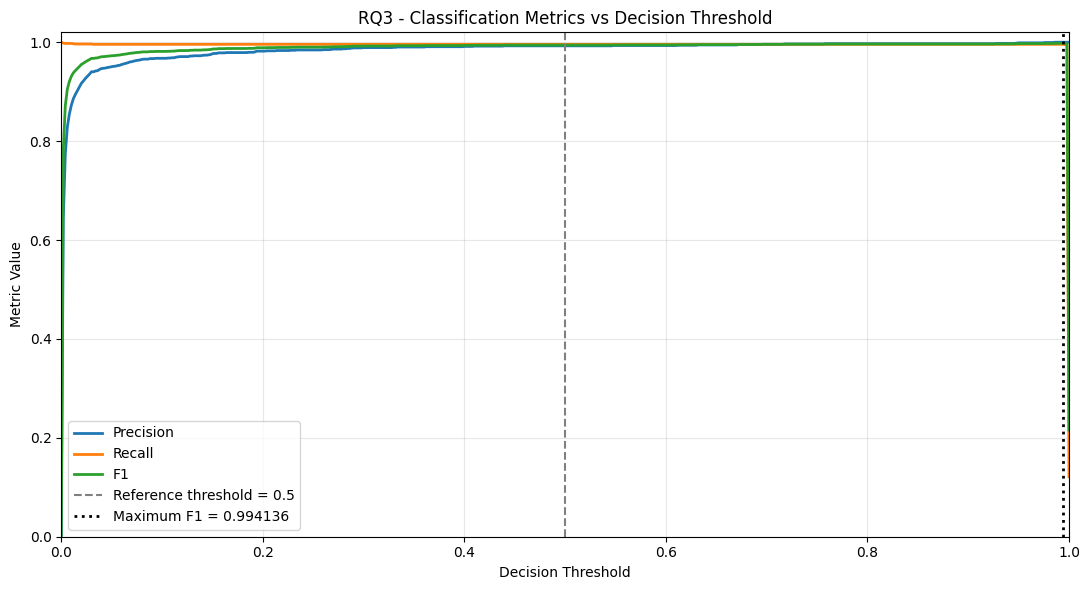

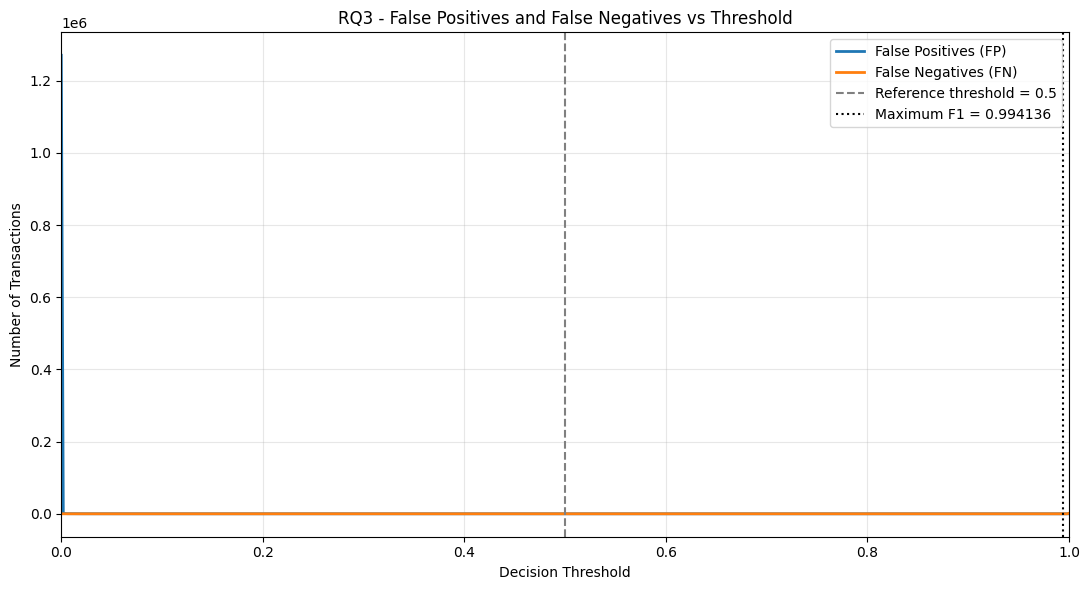

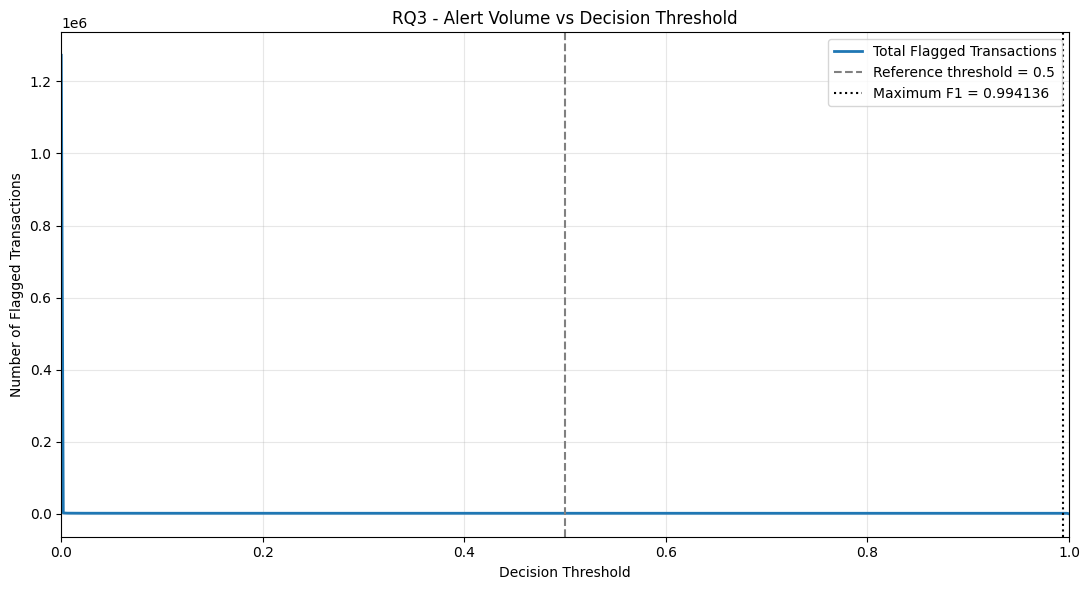

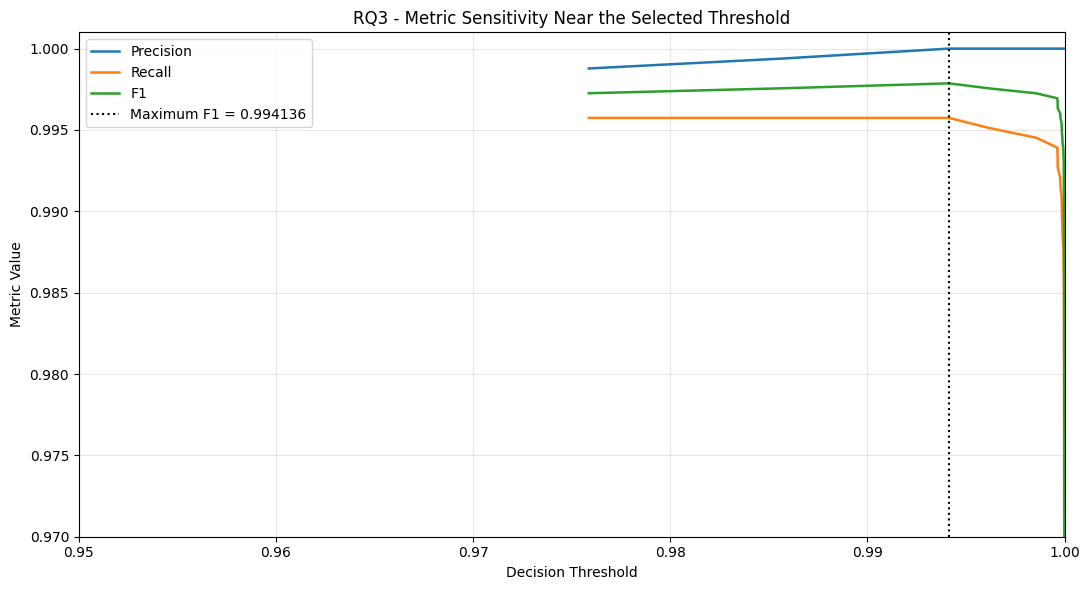

RQ3-06 — VISUALIZATION COMPLETED
Saved: rq3_threshold_metrics.png
Saved: rq3_fp_fn_analysis.png
Saved: rq3_alert_volume.png
Saved: rq3_threshold_metrics_zoom.png

PASS: RQ3-06 completed.


In [8]:

# ============================================================
# RQ3-06 — THRESHOLD SENSITIVITY VISUALIZATION
# ============================================================

# 1. Đọc bảng threshold đã được lưu ở RQ3-05.
plot_path = (
    RQ3_RESULT_DIR / "rq3_threshold_analysis.csv"
)

assert plot_path.is_file()

plot_df = pd.read_csv(plot_path)

required_columns = [
    "Threshold", "Precision", "Recall", "F1",
    "TP", "FP", "FN", "TN", "Alerts"
]

assert set(required_columns).issubset(plot_df.columns)

# Đọc threshold Max-F1 từ RQ3-05.
assert 0 <= best_threshold <= 1

# ------------------------------------------------------------
# FIGURE 1 — PRECISION, RECALL, F1 (FULL RANGE)
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for metric in ["Precision", "Recall", "F1"]:
    ax.plot(
        plot_df["Threshold"],
        plot_df[metric],
        linewidth=2,
        label=metric
    )

ax.axvline(
    THRESHOLD_REFERENCE,
    color="gray",
    linestyle="--",
    label="Reference threshold = 0.5"
)

ax.axvline(
    best_threshold,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Maximum F1 = {best_threshold:.6f}"
)

ax.set_title(
    "RQ3 - Classification Metrics vs Decision Threshold"
)

ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Metric Value")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_1 = (
    RQ3_FIGURE_DIR / "rq3_threshold_metrics.png"
)

plt.savefig(
    figure_1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 2 — FALSE POSITIVES AND FALSE NEGATIVES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_df["Threshold"],
    plot_df["FP"],
    label="False Positives (FP)",
    linewidth=2
)

ax.plot(
    plot_df["Threshold"],
    plot_df["FN"],
    label="False Negatives (FN)",
    linewidth=2
)

ax.axvline(
    THRESHOLD_REFERENCE,
    color="gray",
    linestyle="--",
    label="Reference threshold = 0.5"
)

ax.axvline(
    best_threshold,
    color="black",
    linestyle=":",
    label=f"Maximum F1 = {best_threshold:.6f}"
)

ax.set_title(
    "RQ3 - False Positives and False Negatives vs Threshold"
)

ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Number of Transactions")
ax.set_xlim(0, 1)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_2 = (
    RQ3_FIGURE_DIR / "rq3_fp_fn_analysis.png"
)

plt.savefig(
    figure_2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 3 — TOTAL ALERT VOLUME
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_df["Threshold"],
    plot_df["Alerts"],
    linewidth=2,
    label="Total Flagged Transactions"
)

ax.axvline(
    THRESHOLD_REFERENCE,
    color="gray",
    linestyle="--",
    label="Reference threshold = 0.5"
)

ax.axvline(
    best_threshold,
    color="black",
    linestyle=":",
    label=f"Maximum F1 = {best_threshold:.6f}"
)

ax.set_title(
    "RQ3 - Alert Volume vs Decision Threshold"
)

ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Number of Flagged Transactions")
ax.set_xlim(0, 1)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_3 = (
    RQ3_FIGURE_DIR / "rq3_alert_volume.png"
)

plt.savefig(
    figure_3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 4 — ZOOM INTO HIGH-THRESHOLD REGION
# ------------------------------------------------------------
# Bảng exact_df của RQ3-05 chứa các ngưỡng
# được xác định từ fraud scores thực tế.

zoom_df = exact_df.loc[
    (exact_df["Threshold"] >= 0.95) &
    (exact_df["Threshold"] <= 1.0)
].copy()

assert not zoom_df.empty

fig, ax = plt.subplots(figsize=(11, 6))

for metric in ["Precision", "Recall", "F1"]:
    ax.plot(
        zoom_df["Threshold"],
        zoom_df[metric],
        label=metric,
        linewidth=1.8
    )

ax.axvline(
    best_threshold,
    color="black",
    linestyle=":",
    label=f"Maximum F1 = {best_threshold:.6f}"
)

ax.set_title(
    "RQ3 - Metric Sensitivity Near the Selected Threshold"
)

ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Metric Value")
ax.set_xlim(0.95, 1.0)

# Phóng to trục y để quan sát những thay đổi nhỏ.
ax.set_ylim(0.97, 1.001)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_4 = (
    RQ3_FIGURE_DIR / "rq3_threshold_metrics_zoom.png"
)

plt.savefig(
    figure_4,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 55)
print("RQ3-06 — VISUALIZATION COMPLETED")
print("=" * 55)

for path in [figure_1, figure_2, figure_3, figure_4]:
    assert path.is_file()
    print("Saved:", path.name)

print("\nPASS: RQ3-06 completed.")



### RQ3-07. Threshold Comparison and Operational Implications

**Objective:** Compare the reference threshold with the maximum-F1 threshold and examine the sensitivity of classification outcomes around the selected operating point.

**Input:** Verified Validation labels, fraud scores, baseline metrics, and the maximum-F1 candidate from RQ3-05.

**Procedure:** Recalculate confusion matrix outcomes at the reference and maximum-F1 thresholds, quantify differences in fraud detection and false alerts, and evaluate nearby threshold values. Identify observed thresholds producing equivalent classification outcomes.

**Output:** A reference-versus-optimized comparison table, threshold sensitivity table, and focused false-positive/false-negative visualization.

**Methodological consideration:** False positives represent unnecessary alerts for internal review, not necessarily direct customer inconvenience. Changes in alert counts indicate potential review-volume implications but do not measure actual staff workload or investigation costs.


REFERENCE VS MAXIMUM-F1 THRESHOLD


,Configuration,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Alerts,Alert_Rate,Accuracy
0,Reference_0.5,0.500000,0.992718,0.99574,0.994227,1636,12,7,1270869,1648,0.001295,0.999985
1,Maximum_F1,0.994136,1.000000,0.99574,0.997865,1636,0,7,1270881,1636,0.001286,0.999994



OPERATIONAL IMPLICATIONS ON VALIDATION
Change in detected fraud (TP): 0
Change in missed fraud (FN): 0
Reduction in false alerts (FP): 12
Reduction in total alerts: 12
Alert volume reduction: 0.7282 %

THRESHOLD SENSITIVITY


,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Alerts,Alert_Rate,Is_Selected
0,0.950000,0.998779,0.995740,0.997257,1636,2,7,1270879,1638,0.001287,False
1,0.980000,0.999389,0.995740,0.997561,1636,1,7,1270880,1637,0.001286,False
2,0.984136,0.999389,0.995740,0.997561,1636,1,7,1270880,1637,0.001286,False
3,0.989136,1.000000,0.995740,0.997865,1636,0,7,1270881,1636,0.001286,False
4,0.990000,1.000000,0.995740,0.997865,1636,0,7,1270881,1636,0.001286,False
5,0.993136,1.000000,0.995740,0.997865,1636,0,7,1270881,1636,0.001286,False
6,0.994136,1.000000,0.995740,0.997865,1636,0,7,1270881,1636,0.001286,True
7,0.995000,1.000000,0.995131,0.997559,1635,0,8,1270881,1635,0.001285,False
8,0.995136,1.000000,0.995131,0.997559,1635,0,8,1270881,1635,0.001285,False
9,0.999000,1.000000,0.993914,0.996947,1633,0,10,1270881,1633,0.001283,False



EQUIVALENT OBSERVED THRESHOLDS
Minimum observed candidate: 0.9941363334655762
Maximum observed candidate: 0.9941363334655762
Number of equivalent candidates: 1


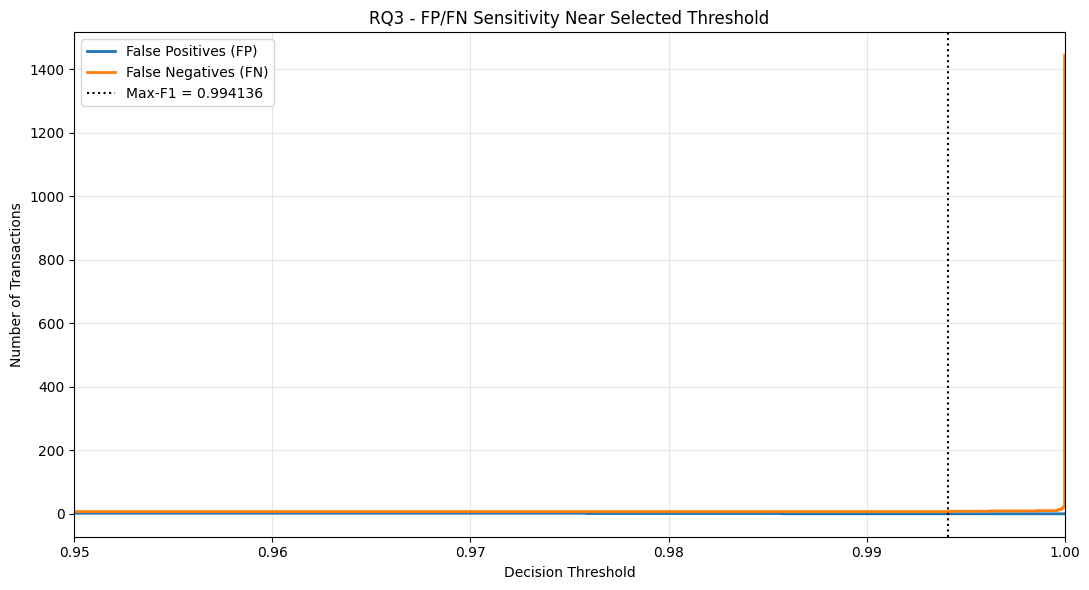


PASS: RQ3-07 completed.


In [9]:

# ============================================================
# RQ3-07 — THRESHOLD COMPARISON AND SENSITIVITY
# ============================================================

# ------------------------------------------------------------
# STEP 1. Đánh giá hai threshold chính
# ------------------------------------------------------------

reference_result = evaluate_threshold(
    y_val,
    fraud_scores,
    THRESHOLD_REFERENCE
)

selected_result = evaluate_threshold(
    y_val,
    fraud_scores,
    best_threshold
)

# Đảm bảo threshold Max-F1 khớp RQ3-05.
assert np.isclose(
    selected_result["F1"],
    best_candidate["F1"],
    atol=1e-12
)

for metric in ["TP", "FP", "FN", "TN", "Alerts"]:
    assert (
        selected_result[metric] == best_candidate[metric]
    ), f"Mismatch in {metric}"

# ------------------------------------------------------------
# STEP 2. Tạo bảng so sánh
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    {
        "Configuration": "Reference_0.5",
        **reference_result
    },
    {
        "Configuration": "Maximum_F1",
        **selected_result
    }
])

comparison_columns = [
    "Configuration", "Threshold",
    "Precision", "Recall", "F1",
    "TP", "FP", "FN", "TN",
    "Alerts", "Alert_Rate", "Accuracy"
]

comparison_df = comparison_df[comparison_columns]

comparison_path = (
    RQ3_RESULT_DIR / "rq3_threshold_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("REFERENCE VS MAXIMUM-F1 THRESHOLD")
display(comparison_df.round(6))

# ------------------------------------------------------------
# STEP 3. Đo mức thay đổi về số giao dịch
# ------------------------------------------------------------

fp_reduction = (
    reference_result["FP"] - selected_result["FP"]
)

fn_change = (
    selected_result["FN"] - reference_result["FN"]
)

tp_change = (
    selected_result["TP"] - reference_result["TP"]
)

alert_reduction = (
    reference_result["Alerts"] - selected_result["Alerts"]
)

alert_reduction_pct = (
    100 * alert_reduction / reference_result["Alerts"]
    if reference_result["Alerts"] > 0
    else 0.0
)

print("\nOPERATIONAL IMPLICATIONS ON VALIDATION")
print("Change in detected fraud (TP):", tp_change)
print("Change in missed fraud (FN):", fn_change)
print("Reduction in false alerts (FP):", fp_reduction)
print("Reduction in total alerts:", alert_reduction)

print(
    "Alert volume reduction:",
    round(alert_reduction_pct, 4), "%"
)

# Không suy diễn trực tiếp thành số giờ lao động tiết kiệm.
# Không kết luận đây là mức giảm thực tế tại ngân hàng.

# ------------------------------------------------------------
# STEP 4. Kiểm tra các threshold quanh Max-F1
# ------------------------------------------------------------

sensitivity_thresholds = [
    best_threshold - 0.01,
    best_threshold - 0.005,
    best_threshold - 0.001,
    best_threshold,
    best_threshold + 0.001,
    best_threshold + 0.005,
    best_threshold + 0.01
]

# Thêm các ngưỡng tham khảo dễ giải thích.
sensitivity_thresholds += [
    0.95, 0.98, 0.99, 0.995, 0.999, 1.0
]

# Giữ các threshold trong [0, 1].
sensitivity_thresholds = np.clip(
    sensitivity_thresholds,
    0.0,
    1.0
)

sensitivity_thresholds = np.unique(
    sensitivity_thresholds
)

sensitivity_df = calculate_threshold_table(
    sensitivity_thresholds
)

# Đánh dấu threshold được chọn.
sensitivity_df["Is_Selected"] = np.isclose(
    sensitivity_df["Threshold"],
    best_threshold,
    rtol=0,
    atol=1e-12
)

sensitivity_path = (
    RQ3_RESULT_DIR / "rq3_threshold_sensitivity.csv"
)

sensitivity_df.to_csv(
    sensitivity_path,
    index=False
)

print("\nTHRESHOLD SENSITIVITY")
display(sensitivity_df.round(6))

# ------------------------------------------------------------
# STEP 5. Xác định những ngưỡng quan sát có cùng
# confusion matrix với threshold Max-F1.
# ------------------------------------------------------------

equivalent_df = exact_df.loc[
    (exact_df["TP"] == selected_result["TP"]) &
    (exact_df["FP"] == selected_result["FP"]) &
    (exact_df["FN"] == selected_result["FN"]) &
    (exact_df["TN"] == selected_result["TN"])
].copy()

assert not equivalent_df.empty

equivalent_min = float(
    equivalent_df["Threshold"].min()
)

equivalent_max = float(
    equivalent_df["Threshold"].max()
)

print("\nEQUIVALENT OBSERVED THRESHOLDS")
print("Minimum observed candidate:", equivalent_min)
print("Maximum observed candidate:", equivalent_max)
print("Number of equivalent candidates:", len(equivalent_df))

# Đây là khoảng giá trị ứng viên đã quan sát có cùng
# confusion matrix, KHÔNG phải khoảng tin cậy thống kê.

# ------------------------------------------------------------
# STEP 6. Biểu đồ FP/FN vùng threshold cao
# ------------------------------------------------------------

zoom_errors = calculate_threshold_table(
    np.linspace(0.95, 1.0, 1001)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.step(
    zoom_errors["Threshold"],
    zoom_errors["FP"],
    where="post",
    label="False Positives (FP)",
    linewidth=2
)

ax.step(
    zoom_errors["Threshold"],
    zoom_errors["FN"],
    where="post",
    label="False Negatives (FN)",
    linewidth=2
)

ax.axvline(
    best_threshold,
    color="black",
    linestyle=":",
    label=f"Max-F1 = {best_threshold:.6f}"
)

ax.set_title(
    "RQ3 - FP/FN Sensitivity Near Selected Threshold"
)

ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Number of Transactions")
ax.set_xlim(0.95, 1.0)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

sensitivity_figure_path = (
    RQ3_FIGURE_DIR / "rq3_fp_fn_sensitivity.png"
)

plt.savefig(
    sensitivity_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# STEP 7. Kiểm tra và hoàn thành
# ------------------------------------------------------------

assert comparison_path.is_file()
assert sensitivity_path.is_file()
assert sensitivity_figure_path.is_file()

print("\nPASS: RQ3-07 completed.")



### RQ3-08. Final Threshold Selection and Configuration Handoff

**Objective:** Finalize the decision threshold selected through the predefined maximum-F1 criterion and prepare a reproducible configuration for held-out test evaluation.

**Input:** RQ2 model selection metadata, RQ3 threshold analysis results, maximum-F1 candidate, and validated threshold comparison outputs.

**Procedure:** Verify the selected threshold against the exact validation threshold analysis, confirm its classification outcomes, validate the associated model artifacts, and save the final configuration.

**Output:** `selected_threshold.json` and `rq3_selection_summary.csv`.

**Selection criterion:** Maximum F1-score on Validation, with the largest observed threshold selected among candidates achieving the same maximum F1-score.

**Methodological consideration:** Operational implications are discussed using false positives, false negatives, and alert counts. These analyses do not change the predefined threshold selection criterion. The held-out Test dataset remains unused until Final Model Evaluation.


In [10]:

# ============================================================
# RQ3-08 — FINAL THRESHOLD SELECTION AND HANDOFF
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1. Xác nhận threshold đạt Maximum F1
# ------------------------------------------------------------

assert 0.0 <= best_threshold <= 1.0

# Xác định F1 lớn nhất từ toàn bộ ứng viên thực tế.
verified_max_f1 = float(exact_df["F1"].max())

# Đánh giá lại threshold được lựa chọn.
final_metrics = evaluate_threshold(
    y_val,
    fraud_scores,
    best_threshold
)

assert np.isclose(
    final_metrics["F1"],
    verified_max_f1,
    rtol=0,
    atol=1e-12
), "Selected threshold does not maximize Validation F1."

# Xác minh lại quy tắc tie-break từ RQ3-05.
max_f1_candidates = exact_df.loc[
    np.isclose(
        exact_df["F1"],
        verified_max_f1,
        rtol=0,
        atol=1e-12
    )
]

expected_threshold = float(
    max_f1_candidates["Threshold"].max()
)

assert np.isclose(
    best_threshold,
    expected_threshold,
    rtol=0,
    atol=1e-12
), "Threshold does not match the predefined tie-break rule."

# ------------------------------------------------------------
# STEP 2. Đối chiếu metrics với kết quả RQ3-05
# ------------------------------------------------------------

assert np.isclose(
    final_metrics["Precision"],
    best_candidate["Precision"],
    atol=1e-12
)

assert np.isclose(
    final_metrics["Recall"],
    best_candidate["Recall"],
    atol=1e-12
)

for metric in ["TP", "FP", "FN", "TN", "Alerts"]:
    assert (
        final_metrics[metric] == best_candidate[metric]
    ), f"Mismatch in {metric}"

# ------------------------------------------------------------
# STEP 3. Xác minh model và các artifact
# ------------------------------------------------------------

assert selected_model_path.is_file()
assert selected_scores_path.is_file()
assert selected_preprocessor_path.is_file()
assert validation_data_path.is_file()

# Xác nhận các kết quả nghiên cứu cần thiết đã lưu.
required_outputs = [
    RQ3_RESULT_DIR / "rq3_baseline_metrics.json",
    RQ3_RESULT_DIR / "rq3_threshold_analysis.csv",
    RQ3_RESULT_DIR / "rq3_max_f1_candidate.json",
    RQ3_RESULT_DIR / "rq3_threshold_comparison.csv",
    RQ3_RESULT_DIR / "rq3_threshold_sensitivity.csv"
]

for path in required_outputs:
    assert path.is_file(), f"Missing RQ3 output: {path}"

# ------------------------------------------------------------
# STEP 4. Tạo cấu hình chính thức cho Final Evaluation
# ------------------------------------------------------------

selected_threshold_config = {
    "research_question": "RQ3",

    "selected_algorithm": "XGBoost",
    "selected_imbalance_strategy": "Class_Weight",

    "preprocessing_family": "Tree",
    "feature_set": "Full_Features",

    "selection_dataset": "Validation_20pct",
    "selection_metric": "F1",

    "selection_rule": "Maximum_Validation_F1",

    "tie_break_rule": (
        "Largest_observed_threshold_among_equal_maximum_F1"
    ),

    "reference_threshold": float(
        THRESHOLD_REFERENCE
    ),

    "selected_threshold": float(
        best_threshold
    ),

    "validation_metrics": {
        "Accuracy": float(final_metrics["Accuracy"]),
        "Precision": float(final_metrics["Precision"]),
        "Recall": float(final_metrics["Recall"]),
        "F1": float(final_metrics["F1"]),
        "AP": float(baseline_metrics["AP"]),
        "ROC_AUC": float(baseline_metrics["ROC_AUC"]),
        "TP": int(final_metrics["TP"]),
        "FP": int(final_metrics["FP"]),
        "FN": int(final_metrics["FN"]),
        "TN": int(final_metrics["TN"]),
        "Alerts": int(final_metrics["Alerts"]),
        "Alert_Rate": float(final_metrics["Alert_Rate"])
    },

    "reference_metrics": {
        "Precision": float(reference_result["Precision"]),
        "Recall": float(reference_result["Recall"]),
        "F1": float(reference_result["F1"]),
        "TP": int(reference_result["TP"]),
        "FP": int(reference_result["FP"]),
        "FN": int(reference_result["FN"]),
        "Alerts": int(reference_result["Alerts"])
    },

    "model_path": str(selected_model_path),
    "preprocessor_path": str(
        selected_preprocessor_path
    ),

    "validation_scores_path": str(
        selected_scores_path
    ),

    "target_column": TARGET,
    "random_state": SEED,

    "prediction_rule": (
        "Flag transaction if fraud_score >= selected_threshold"
    ),

    "system_scope": (
        "Post-Transaction Fraud Detection "
        "and Review Support"
    ),

    "test_used_for_selection": False,

    "limitations": [
        "Threshold optimized on Validation only.",
        "Validation metrics are not independent test estimates.",
        "Fraud scores are not assumed to be calibrated probabilities.",
        "False alerts approximate potential unnecessary review cases.",
        "Actual bank staff workload reduction was not measured.",
        "Performance on unseen transactions requires held-out test evaluation."
    ]
}

# ------------------------------------------------------------
# STEP 5. Lưu selected_threshold.json
# ------------------------------------------------------------

selection_output_path = (
    RQ3_RESULT_DIR / "selected_threshold.json"
)

with open(
    selection_output_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        selected_threshold_config,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# STEP 6. Lưu bảng lựa chọn ngắn gọn
# ------------------------------------------------------------

selection_summary = pd.DataFrame([{
    "Algorithm": "XGBoost",
    "Imbalance_Strategy": "Class_Weight",
    "Selected_Threshold": float(best_threshold),
    "Selection_Metric": "F1",
    "Validation_F1": float(final_metrics["F1"]),
    "Validation_Precision": float(final_metrics["Precision"]),
    "Validation_Recall": float(final_metrics["Recall"]),
    "TP": int(final_metrics["TP"]),
    "FP": int(final_metrics["FP"]),
    "FN": int(final_metrics["FN"]),
    "Alerts": int(final_metrics["Alerts"]),
    "Test_Used": False
}])

summary_output_path = (
    RQ3_RESULT_DIR / "rq3_selection_summary.csv"
)

selection_summary.to_csv(
    summary_output_path,
    index=False
)

# ------------------------------------------------------------
# STEP 7. Kiểm toán file JSON đã lưu
# ------------------------------------------------------------

with open(
    selection_output_path,
    "r",
    encoding="utf-8"
) as f:
    saved_config = json.load(f)

assert saved_config["research_question"] == "RQ3"

assert saved_config["test_used_for_selection"] is False

assert np.isclose(
    saved_config["selected_threshold"],
    best_threshold,
    rtol=0,
    atol=1e-12
)

assert (
    saved_config["model_path"]
    == str(selected_model_path)
)

print("=" * 60)
print("RQ3 — FINAL THRESHOLD SELECTION COMPLETED")
print("=" * 60)

print("Selected Algorithm: XGBoost")
print("Imbalance Strategy: Class_Weight")

print(
    "Selected Threshold:",
    format(best_threshold, ".12g")
)

print("\nVALIDATION PERFORMANCE")

print("Precision:", round(final_metrics["Precision"], 6))
print("Recall:", round(final_metrics["Recall"], 6))
print("F1:", round(final_metrics["F1"], 6))

print("\nTP:", final_metrics["TP"])
print("FP:", final_metrics["FP"])
print("FN:", final_metrics["FN"])
print("TN:", final_metrics["TN"])
print("Total Alerts:", final_metrics["Alerts"])

print("\nSaved outputs:")
print("1.", selection_output_path)
print("2.", summary_output_path)

print("\nPASS: RQ3 is ready for Final Model Evaluation.")


RQ3 — FINAL THRESHOLD SELECTION COMPLETED
Selected Algorithm: XGBoost
Imbalance Strategy: Class_Weight
Selected Threshold: 0.994136333466

VALIDATION PERFORMANCE
Precision: 1.0
Recall: 0.99574
F1: 0.997865

TP: 1636
FP: 0
FN: 7
TN: 1270881
Total Alerts: 1636

Saved outputs:
1. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results/selected_threshold.json
2. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ3/results/rq3_selection_summary.csv

PASS: RQ3 is ready for Final Model Evaluation.
